### Импорты

In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from pathlib import Path
import importlib

import metrics, baselines, my_evaluate
importlib.reload(metrics)
importlib.reload(baselines)
importlib.reload(my_evaluate)

from metrics import build_eval_targets, build_context, evaluate_model
from baselines import (
    popularity_baseline, recent_popularity_at_cutoff,
    last_item_baseline, pure_last_item_baseline, item_knn_baseline,
)
from my_evaluate import GPT2Predictor, evaluate_gpt2_fast
from dataset import build_item_vocab
from model import create_model

PROC = Path('../data/processed')
RESULTS = Path('../results')

train = pd.read_parquet(PROC / 'train.parquet')
val = pd.read_parquet(PROC / 'val.parquet')
test = pd.read_parquet(PROC / 'test.parquet')

item2idx, idx2item = build_item_vocab(train)
vocab_size = len(item2idx) + 2

### Таргеты и контексты

In [2]:
val_targets = build_eval_targets(val)
test_targets = build_eval_targets(test)
val_context = build_context(train)
test_context = build_context(train, val)

T1 = pd.Timestamp('2021-07-24')  # val cutoff
T2 = pd.Timestamp('2021-08-04')  # test cutoff

print(f"Val targets: {len(val_targets):,}")
print(f"Test targets: {len(test_targets):,}")

Val targets: 176,224
Test targets: 186,690


### Подбор окна Recent-Pop на val

In [3]:
# Подбjh окна ТОЛЬКО на val, потом применение к test
for window in [3, 7, 14, 28]:
    predict_fn = recent_popularity_at_cutoff(train, T1, window_days=window, top_n=500)
    m = evaluate_model(predict_fn, val_targets, val_context, verbose=False)
    print(f"window={window:2d} days: NDCG@10 = {m['NDCG@10']:.4f}, "
          f"Recall@10 = {m['Recall@10']:.4f}")

window= 3 days: NDCG@10 = 0.1190, Recall@10 = 0.2110
window= 7 days: NDCG@10 = 0.1176, Recall@10 = 0.2067
window=14 days: NDCG@10 = 0.1174, Recall@10 = 0.2082
window=28 days: NDCG@10 = 0.1153, Recall@10 = 0.2020


### Все бейзлайны с маскировкой на test

In [4]:
BEST_WINDOW = 3

train_val = pd.concat([train, val], ignore_index=True)

baseline_fns = {
    'Popularity': popularity_baseline(train, top_n=500),
    'Recent-Popularity': recent_popularity_at_cutoff(train_val, T2, window_days=7, top_n=500),
    'Pure Last-Item': pure_last_item_baseline(train),
    'Item-kNN': item_knn_baseline(train, top_k_similar=50, top_n=500),
}

results = {}
for name, fn in baseline_fns.items():
    print(f"=== {name} ===")
    m = evaluate_model(fn, test_targets, test_context, verbose=False)
    results[name] = m
    for k, v in m.items():
        print(f"  {k:>12s}: {v:.4f}")
    print()

results_df = pd.DataFrame(results).round(4)
print(results_df.to_string())
results_df.to_csv(RESULTS / 'baselines_v3_masked.csv')

=== Popularity ===
     Recall@10: 0.1726
       NDCG@10: 0.1032
        MAP@10: 0.0814
     Recall@50: 0.2871
       NDCG@50: 0.1279
        MAP@50: 0.0863
    Recall@100: 0.3529
      NDCG@100: 0.1386
       MAP@100: 0.0873

=== Recent-Popularity ===
     Recall@10: 0.2230
       NDCG@10: 0.1229
        MAP@10: 0.0923
     Recall@50: 0.3436
       NDCG@50: 0.1498
        MAP@50: 0.0981
    Recall@100: 0.4190
      NDCG@100: 0.1620
       MAP@100: 0.0992

=== Pure Last-Item ===
     Recall@10: 0.0000
       NDCG@10: 0.0000
        MAP@10: 0.0000
     Recall@50: 0.0000
       NDCG@50: 0.0000
        MAP@50: 0.0000
    Recall@100: 0.0000
      NDCG@100: 0.0000
       MAP@100: 0.0000

=== Item-kNN ===
     Recall@10: 0.1842
       NDCG@10: 0.1091
        MAP@10: 0.0859
     Recall@50: 0.3402
       NDCG@50: 0.1429
        MAP@50: 0.0929
    Recall@100: 0.4298
      NDCG@100: 0.1575
       MAP@100: 0.0942

            Popularity  Recent-Popularity  Pure Last-Item  Item-kNN
Recall@10      

### Сколько просмотренного в топ-10 GPT-2

In [5]:
# Это покажет, что изменится после маскировки
model = create_model(vocab_size=vocab_size)
state = torch.load(RESULTS / 'checkpoints' / 'best_model.pt', map_location='cpu')
model.load_state_dict(state)

predictor = GPT2Predictor(model, item2idx, idx2item, max_len=50)

# Подвыборка 1000 юзеров для скорости
sample_users = test_targets['user_id'].unique()[:1000]
test_small = test_targets[test_targets['user_id'].isin(sample_users)]

# БЕЗ маскировки
preds_no_mask = evaluate_gpt2_fast(predictor, test_small, test_context, k=100, batch_size=256, exclude_seen=False)
# маскировка в predict_batch уже включена — но нужно БЕЗ маскировки для диагностики
# Пока - пропуск, простой подсчёт «seen rate» по preds_no_mask

# Доля просмотренного в топ-10
seen_rates = []
for user_id in sample_users:
    ctx = test_context.get(user_id, {'items': []})
    seen = set(ctx['items'])
    preds = preds_no_mask.get(user_id, [])[:10]
    if preds:
        seen_rates.append(len(set(preds) & seen) / len(preds))

print(f"Средняя доля просмотренного в топ-10 GPT-2 (без маскировки): {np.mean(seen_rates)*100:.1f}%")

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 14936), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 14936), got 50256. This may result in unexpected behavior.


Уникальных юзеров для оценки: 1,000


predict_batch:   0%|          | 0/4 [00:00<?, ?it/s]

Средняя доля просмотренного в топ-10 GPT-2 (без маскировки): 16.7%


### GPT-2 с маскировкой на test

In [6]:
# Полный прогон с маскировкой (внутри predict_batch она уже включена)
test_preds_masked = evaluate_gpt2_fast(
    predictor, test_targets, test_context, k=100, batch_size=512
)

# Счёт метрик
def compute_metrics(preds_dict, targets_df, k_values=(10, 50, 100)):
    max_k = max(k_values)
    accum = {f'{m}@{k}': [] for k in k_values for m in ['Recall', 'NDCG', 'MAP']}
    for _, row in targets_df.iterrows():
        preds = preds_dict.get(row['user_id'], [])[:max_k]
        target = row['item_id']
        for k in k_values:
            accum[f'Recall@{k}'].append(metrics.recall_at_k(preds, target, k))
            accum[f'NDCG@{k}'].append(metrics.ndcg_at_k(preds, target, k))
            accum[f'MAP@{k}'].append(metrics.average_precision_at_k(preds, target, k))
    return {k: float(np.mean(v)) for k, v in accum.items()}

gpt2_masked = compute_metrics(test_preds_masked, test_targets)
print("GPT-2 с маскировкой на test:")
for k, v in gpt2_masked.items():
    print(f"  {k:>12s}: {v:.4f}")

# Сводная таблица
results_df['GPT-2'] = pd.Series(gpt2_masked)
print("\n=== Финальная таблица (всё с маскировкой) ===")
print(results_df.round(4).to_string())
results_df.to_csv(RESULTS / 'final_v3.csv')

Уникальных юзеров для оценки: 132,323


predict_batch:   0%|          | 0/259 [00:00<?, ?it/s]

GPT-2 с маскировкой на test:
     Recall@10: 0.2175
       NDCG@10: 0.1292
        MAP@10: 0.1020
     Recall@50: 0.3699
       NDCG@50: 0.1625
        MAP@50: 0.1090
    Recall@100: 0.4557
      NDCG@100: 0.1764
       MAP@100: 0.1102

=== Финальная таблица (всё с маскировкой) ===
            Popularity  Recent-Popularity  Pure Last-Item  Item-kNN   GPT-2
Recall@10       0.1726             0.2230             0.0    0.1842  0.2175
NDCG@10         0.1032             0.1229             0.0    0.1091  0.1292
MAP@10          0.0814             0.0923             0.0    0.0859  0.1020
Recall@50       0.2871             0.3436             0.0    0.3402  0.3699
NDCG@50         0.1279             0.1498             0.0    0.1429  0.1625
MAP@50          0.0863             0.0981             0.0    0.0929  0.1090
Recall@100      0.3529             0.4190             0.0    0.4298  0.4557
NDCG@100        0.1386             0.1620             0.0    0.1575  0.1764
MAP@100         0.0873           

### Красивая картинка

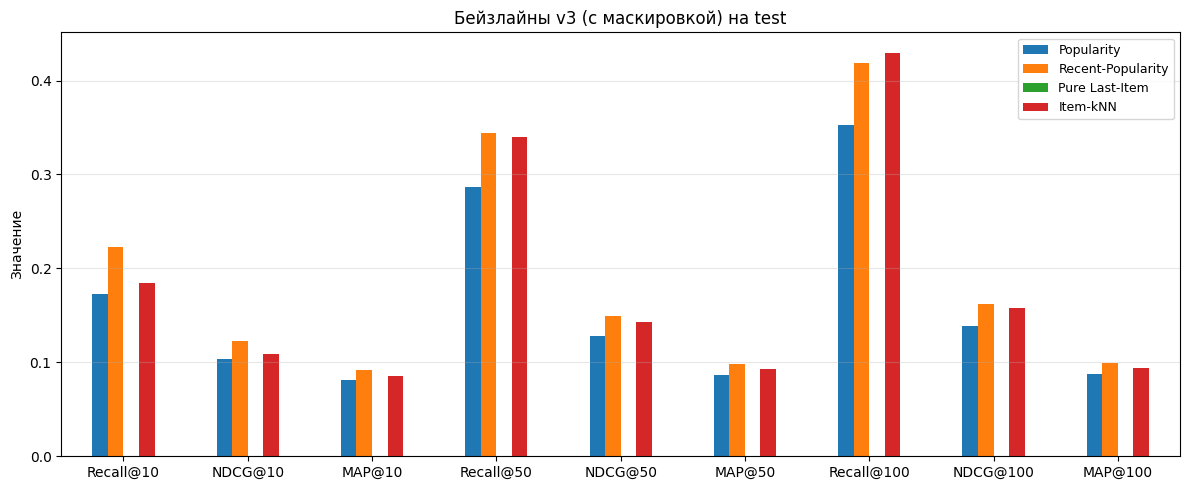

Сохранено: ..\results\baselines_v3_masked.png


In [7]:
baselines_df = pd.read_csv(RESULTS / 'baselines_v3_masked.csv', index_col=0)

fig, ax = plt.subplots(figsize=(12, 5))
baselines_df.plot(kind='bar', ax=ax, rot=0)
ax.set_title('Бейзлайны v3 (с маскировкой) на test')
ax.set_ylabel('Значение')
ax.grid(axis='y', alpha=0.3)
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig(RESULTS / 'baselines_v3_masked.png', dpi=100)
plt.show()
print(f"Сохранено: {RESULTS / 'baselines_v3_masked.png'}")